In [157]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,sampleid,age,workclass,fnlwgt,education,educational_num,marital_status,occupation,relationship,race,gender,capital_gain,capital_loss,hours_per_week,native_country,income,profile_description
0,34343,71,Private,77253,HS-grad,9,Never-married,Handlers-cleaners,Not-in-family,White,Male,0,0,17,United-States,<=50K,welding analysis operations timber crane certi...
1,18560,17,Private,329783,10th,6,Never-married,Sales,Other-relative,White,Female,0,0,10,United-States,<=50K,merger KPI leverage management certified profe...
2,12478,27,Private,91257,HS-grad,9,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40,El-Salvador,<=50K,support garnish turndown experience concierge
3,561,43,Private,125577,HS-grad,9,Separated,Adm-clerical,Unmarried,Black,Female,0,0,40,United-States,<=50K,floral amenity concierge linen training operat...
4,3428,31,Private,137978,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40,United-States,<=50K,margin monitoring merger maintenance portfolio


In [158]:
subtask1 = df_train[df_train.income == ">50K"].native_country.value_counts().index[1]

occupations = ['Handlers-cleaners', 'Sales', 'Other-service', 'Adm-clerical', 'Exec-managerial', 'Prof-specialty', 'Craft-repair',
       'Machine-op-inspct', 'Farming-fishing', 'Transport-moving', 'Tech-support', 'Protective-serv', 'Priv-house-serv', 'Armed-Forces']
rate = {}
for occ in occupations:
    nr_pers = df_train.occupation.value_counts()[occ]
    nr_pers_venit = df_train[df_train.income == ">50K"].occupation.value_counts()[occ]
    rate[occ] = nr_pers_venit/nr_pers

subtask2 = max(rate, key=rate.get)

df_1 = pd.DataFrame({
    "subtaskID": [1, 2],
    "datapointID": [1, 2],
    "answer": [subtask1, subtask2]
})

df_1

,subtaskID,datapointID,answer
0,1,1,Philippines
1,2,2,Exec-managerial


In [159]:
#preprocessing

df_train.workclass = df_train.workclass.fillna(df_train.workclass.mode()[0])
df_test.workclass = df_test.workclass.fillna(df_test.workclass.mode()[0])

df_train.occupation = df_train.occupation.fillna(df_train.occupation.mode()[0])
df_test.occupation = df_test.occupation.fillna(df_test.occupation.mode()[0])

df_train.native_country = df_train.native_country.fillna(df_train.native_country.mode()[0])
df_test.native_country = df_test.native_country.fillna(df_test.native_country.mode()[0])

from sklearn.preprocessing import LabelEncoder
to_enc = ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'gender', 'native_country']
for col in to_enc:
    enc = LabelEncoder()
    df_train[col] = enc.fit_transform(df_train[col])
    df_test[col] = enc.transform(df_test[col])

df_train.head()

,sampleid,age,workclass,fnlwgt,education,educational_num,marital_status,occupation,relationship,race,gender,capital_gain,capital_loss,hours_per_week,native_country,income,profile_description
0,34343,71,3,77253,11,9,4,5,1,4,1,0,0,17,38,<=50K,welding analysis operations timber crane certi...
1,18560,17,3,329783,0,6,4,11,2,4,0,0,0,10,38,<=50K,merger KPI leverage management certified profe...
2,12478,27,3,91257,11,9,2,7,0,4,1,0,0,40,7,<=50K,support garnish turndown experience concierge
3,561,43,3,125577,11,9,5,0,4,2,0,0,0,40,38,<=50K,floral amenity concierge linen training operat...
4,3428,31,3,137978,9,13,2,3,0,4,1,0,0,40,38,<=50K,margin monitoring merger maintenance portfolio


In [160]:
df_train.columns

Index(['sampleid', 'age', 'workclass', 'fnlwgt', 'education',
       'educational_num', 'marital_status', 'occupation', 'relationship',
       'race', 'gender', 'capital_gain', 'capital_loss', 'hours_per_week',
       'native_country', 'income', 'profile_description'],
      dtype='object')

In [161]:
text1 = df_train.profile_description
text2 = df_test.profile_description

from sklearn.feature_extraction.text import TfidfVectorizer

vect = TfidfVectorizer()
X_text = vect.fit_transform(text1)
X_final_text = vect.transform(text2)

X_text

<39073x138 sparse matrix of type '<class 'numpy.float64'>'
	with 253933 stored elements in Compressed Sparse Row format>

In [162]:
features = ['age', 'workclass', 'fnlwgt', 'education', 'educational_num', 'marital_status', 'occupation', 'relationship',
       'race', 'gender', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country']
target = 'income'

X = df_train[features]
y = df_train[target]
X_final = df_test[features]

X.head()

,age,workclass,fnlwgt,education,educational_num,marital_status,occupation,relationship,race,gender,capital_gain,capital_loss,hours_per_week,native_country
0,71,3,77253,11,9,4,5,1,4,1,0,0,17,38
1,17,3,329783,0,6,4,11,2,4,0,0,0,10,38
2,27,3,91257,11,9,2,7,0,4,1,0,0,40,7
3,43,3,125577,11,9,5,0,4,2,0,0,0,40,38
4,31,3,137978,9,13,2,3,0,4,1,0,0,40,38


In [178]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score

model = LGBMClassifier(verbose=-1)

cross_val_score(model, X, y, cv=3, scoring='f1_macro').mean()

0.8131722237413412

In [172]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [173]:
df_2 = pd.DataFrame({
    "subtaskID": 3,
    "datapointID": df_test.sampleid,
    "answer": y_preds
})

df_2.head()

,subtaskID,datapointID,answer
0,3,40343,<=50K
1,3,47681,<=50K
2,3,525,>50K
3,3,8509,<=50K
4,3,31693,>50K


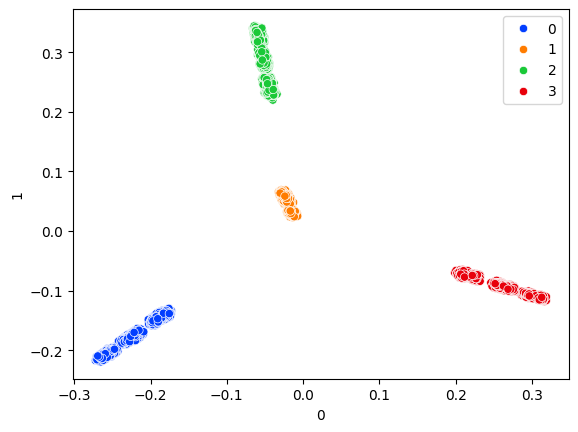

In [174]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

pca = PCA(n_components=2)
X_red = pd.DataFrame(pca.fit_transform(X_text))
X_red_final = pd.DataFrame(pca.transform(X_final_text))

kmeans = KMeans(n_clusters=4, random_state=42)
labels = kmeans.fit_predict(X_final_text)

sns.scatterplot(x=X_red_final[0], y=X_red_final[1], hue=labels, palette='bright')
plt.show()

In [175]:
df_3 = pd.DataFrame({
    "subtaskID": 4,
    "datapointID": df_test.sampleid,
    "answer": labels
})

df_3.head()

,subtaskID,datapointID,answer
0,4,40343,0
1,4,47681,1
2,4,525,1
3,4,8509,3
4,4,31693,1


In [176]:
submission = pd.concat([df_1, df_2, df_3])

submission

,subtaskID,datapointID,answer
0,1,1,Philippines
1,2,2,Exec-managerial
0,3,40343,<=50K
1,3,47681,<=50K
2,3,525,>50K
...,...,...,...
9764,4,20385,3
9765,4,28001,1
9766,4,22164,2
9767,4,24734,0


In [177]:
submission.to_csv("submission.csv", index=False)